In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

print("Libraries Imported Successfully!")

/home/najanrohit0/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
I0000 00:00:1794730168.855759   16470 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794730168.857522   16470 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794730169.088067   16470 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AV

TensorFlow Version: 2.21.0
NumPy Version: 2.1.3
Pandas Version: 2.2.3
Libraries Imported Successfully!


In [2]:
dataset_path = "Energy/household_power_consumption.txt"

df = pd.read_csv(
    dataset_path,
    sep=';',
    low_memory=False,
    na_values=['?']
)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

Dataset Shape: (2075259, 9)

First 5 Rows:
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  

Dataset Information:
<class 'pandas.core.frame.DataFram

In [3]:
# Convert Date and Time into Datetime

df['Datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    dayfirst=True
)

# Select numerical columns

numeric_columns = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

# Convert columns into numeric values

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )

# Set Datetime as index

df = df.set_index('Datetime')

# Convert minute-level data into hourly data

hourly_df = df[numeric_columns].resample('h').mean()

print("Hourly Dataset Shape:", hourly_df.shape)

print("\nMissing Values:")
print(hourly_df.isnull().sum())

print("\nFirst 5 Rows:")
print(hourly_df.head())

Hourly Dataset Shape: (34589, 7)

Missing Values:
Global_active_power      421
Global_reactive_power    421
Voltage                  421
Global_intensity         421
Sub_metering_1           421
Sub_metering_2           421
Sub_metering_3           421
dtype: int64

First 5 Rows:
                     Global_active_power  Global_reactive_power     Voltage  \
Datetime                                                                      
2006-12-16 17:00:00             4.222889               0.229000  234.643889   
2006-12-16 18:00:00             3.632200               0.080033  234.580167   
2006-12-16 19:00:00             3.400233               0.085233  233.232500   
2006-12-16 20:00:00             3.268567               0.075100  234.071500   
2006-12-16 21:00:00             3.056467               0.076667  237.158667   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
Datetime                                                                
2006-12-16 17:00:00

In [4]:
# Handle missing values

hourly_df = hourly_df.interpolate(
    method='linear'
)

hourly_df = hourly_df.ffill().bfill()

print("Missing Values After Preprocessing:")
print(hourly_df.isnull().sum())

print("\nCleaned Dataset Shape:", hourly_df.shape)

print("\nData Preprocessing Completed!")

Missing Values After Preprocessing:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Cleaned Dataset Shape: (34589, 7)

Data Preprocessing Completed!


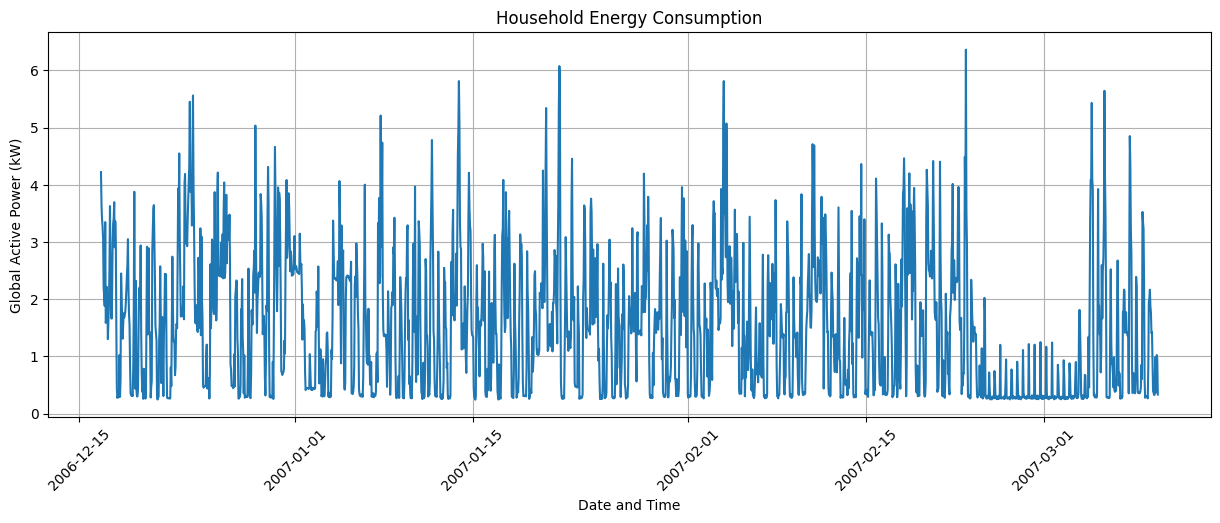

In [5]:
plt.figure(figsize=(15, 5))

plt.plot(
    hourly_df.index[:2000],
    hourly_df['Global_active_power'].iloc[:2000]
)

plt.title("Household Energy Consumption")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kW)")

plt.xticks(rotation=45)
plt.grid()

plt.show()

In [6]:
# Select numerical features

features = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

# Split data chronologically

split_index = int(len(hourly_df) * 0.8)

train_df = hourly_df.iloc[:split_index].copy()
test_df = hourly_df.iloc[split_index:].copy()

print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)

Training Data Shape: (27671, 7)
Testing Data Shape: (6918, 7)


In [7]:
# Initialize MinMaxScaler

scaler = MinMaxScaler()

# Fit scaler on training data only

X_train = scaler.fit_transform(train_df[features])

# Transform testing data

X_test = scaler.transform(test_df[features])

print("Normalized Training Data:", X_train.shape)
print("Normalized Testing Data:", X_test.shape)

print("\nNormalization Completed!")

Normalized Training Data: (27671, 7)
Normalized Testing Data: (6918, 7)

Normalization Completed!


In [8]:
# Input Layer

input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder Network

encoded = Dense(16, activation='relu')(input_layer)

encoded = Dense(8, activation='relu')(encoded)

latent = Dense(3, activation='relu')(encoded)

# Decoder Network

decoded = Dense(8, activation='relu')(latent)

decoded = Dense(16, activation='relu')(decoded)

output_layer = Dense(
    input_dim,
    activation='sigmoid'
)(decoded)

# Create Autoencoder Model

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

# Display Model Architecture

autoencoder.summary()

E0000 00:00:1794730250.331105   16470 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 586 (2.29 KB)

 Trainable params: 586 (2.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("Autoencoder Model Compiled Successfully!")

Autoencoder Model Compiled Successfully!


In [10]:
# Split training data into training and validation

val_index = int(len(X_train) * 0.8)

X_fit = X_train[:val_index]
X_val = X_train[val_index:]

# Early Stopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train Autoencoder

history = autoencoder.fit(
    X_fit,
    X_fit,
    validation_data=(X_val, X_val),
    epochs=30,
    batch_size=64,
    shuffle=True,
    callbacks=[early_stop],
    verbose=1
)

print("Model Training Completed!")

Epoch 1/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0615 - mae: 0.1839 - val_loss: 0.0167 - val_mae: 0.0781
Epoch 2/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0077 - mae: 0.0545 - val_loss: 0.0051 - val_mae: 0.0440
Epoch 3/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0045 - mae: 0.0412 - val_loss: 0.0043 - val_mae: 0.0407
Epoch 4/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0038 - mae: 0.0378 - val_loss: 0.0039 - val_mae: 0.0409
Epoch 5/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0028 - mae: 0.0319 - val_loss: 0.0030 - val_mae: 0.0349
Epoch 6/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0025 - mae: 0.0291 - val_loss: 0.0028 - val_mae: 0.0339
Epoch 7/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0023 - mae: 0.0283 - val_loss: 0.0027 - val_mae: 0.0331
Epoch 8/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0022 - mae: 0.0278 - val_loss: 0.0026 - val_mae: 0.0326
Epoch 9/30
346/346 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - lo

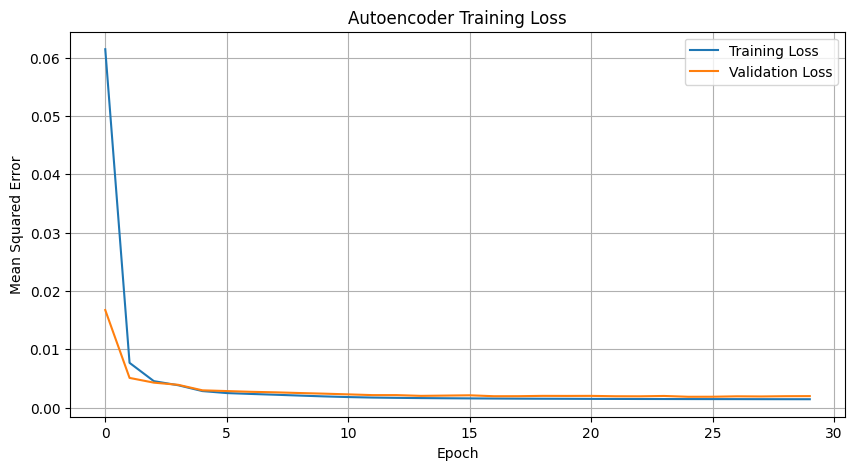

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid()

plt.show()

In [12]:
# Reconstruct Validation Data

val_predictions = autoencoder.predict(X_val)

# Reconstruct Testing Data

test_predictions = autoencoder.predict(X_test)

# Calculate Reconstruction Error

val_errors = np.mean(
    np.square(X_val - val_predictions),
    axis=1
)

test_errors = np.mean(
    np.square(X_test - test_predictions),
    axis=1
)

# Calculate Threshold using Validation Data

threshold = np.percentile(val_errors, 95)

print("Anomaly Threshold:", threshold)

# Detect Anomalies

anomalies = test_errors > threshold

print("\nTotal Test Records:", len(X_test))

print("Normal Records:", np.sum(~anomalies))

print("Abnormal Records:", np.sum(anomalies))

173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 394us/step
Anomaly Threshold: 0.007602206074052916

Total Test Records: 6918
Normal Records: 6735
Abnormal Records: 183


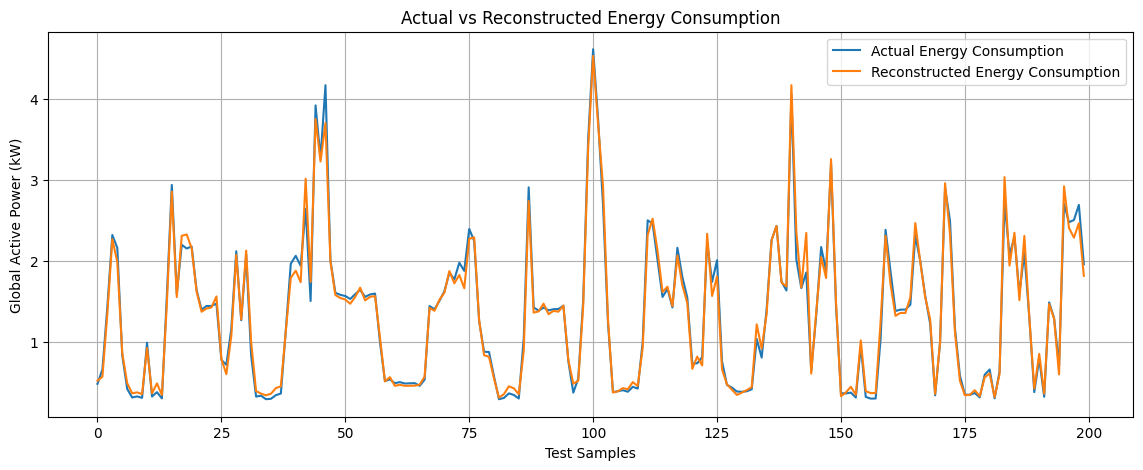

In [13]:
# Convert normalized data back to original scale

actual_values = scaler.inverse_transform(X_test)

reconstructed_values = scaler.inverse_transform(
    test_predictions
)

# Select Global Active Power

plt.figure(figsize=(14, 5))

plt.plot(
    actual_values[:200, 0],
    label='Actual Energy Consumption'
)

plt.plot(
    reconstructed_values[:200, 0],
    label='Reconstructed Energy Consumption'
)

plt.title("Actual vs Reconstructed Energy Consumption")

plt.xlabel("Test Samples")
plt.ylabel("Global Active Power (kW)")

plt.legend()
plt.grid()

plt.show()

Energy Consumption Anomaly Detection Results
              Datetime  Actual_Energy  Reconstructed_Energy  \
0  2010-02-11 16:00:00       0.477733              0.515135   
1  2010-02-11 17:00:00       0.655267              0.565788   
2  2010-02-11 18:00:00       1.436367              1.353081   
3  2010-02-11 19:00:00       2.319900              2.267246   
4  2010-02-11 20:00:00       2.159933              1.985638   
5  2010-02-11 21:00:00       0.829867              0.858328   
6  2010-02-11 22:00:00       0.414267              0.484700   
7  2010-02-11 23:00:00       0.307900              0.360399   
8  2010-02-12 00:00:00       0.321600              0.371174   
9  2010-02-12 01:00:00       0.304100              0.351074   
10 2010-02-12 02:00:00       0.986500              0.920198   
11 2010-02-12 03:00:00       0.320033              0.358859   
12 2010-02-12 04:00:00       0.374567              0.482578   
13 2010-02-12 05:00:00       0.296900              0.338874   
14 2010-02

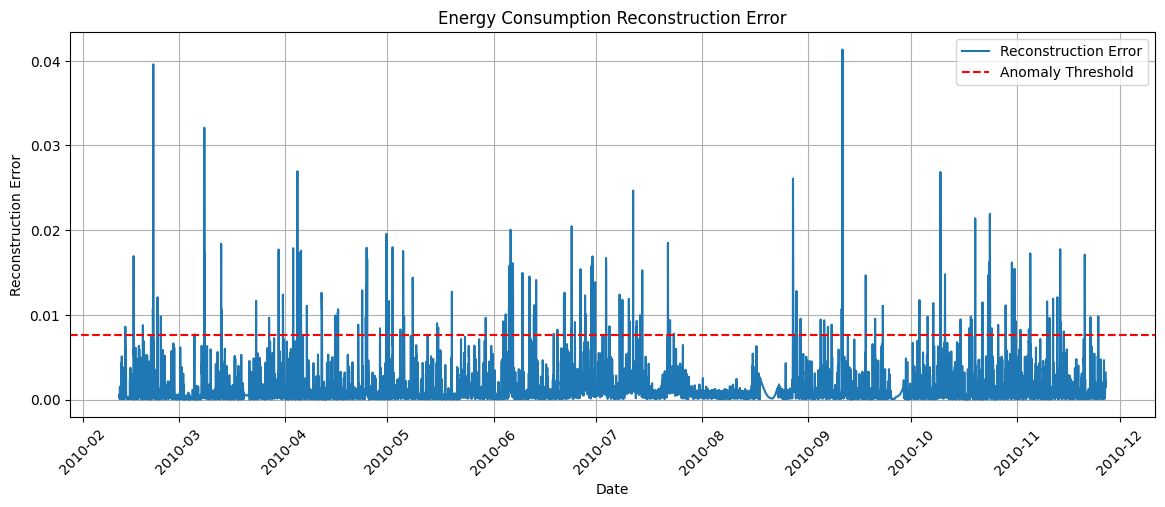

In [14]:
# Create Results DataFrame

results = pd.DataFrame({
    'Datetime': test_df.index,
    'Actual_Energy': actual_values[:, 0],
    'Reconstructed_Energy': reconstructed_values[:, 0],
    'Reconstruction_Error': test_errors,
    'Status': np.where(
        anomalies,
        'Abnormal',
        'Normal'
    )
})

# Display Results

print("Energy Consumption Anomaly Detection Results")

print(results.head(20))

print("\nAnomaly Detection Summary:")

print(results['Status'].value_counts())

# Plot Reconstruction Error

plt.figure(figsize=(14, 5))

plt.plot(
    results['Datetime'],
    results['Reconstruction_Error'],
    label='Reconstruction Error'
)

plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title("Energy Consumption Reconstruction Error")

plt.xlabel("Date")
plt.ylabel("Reconstruction Error")

plt.legend()
plt.grid()

plt.xticks(rotation=45)

plt.show()

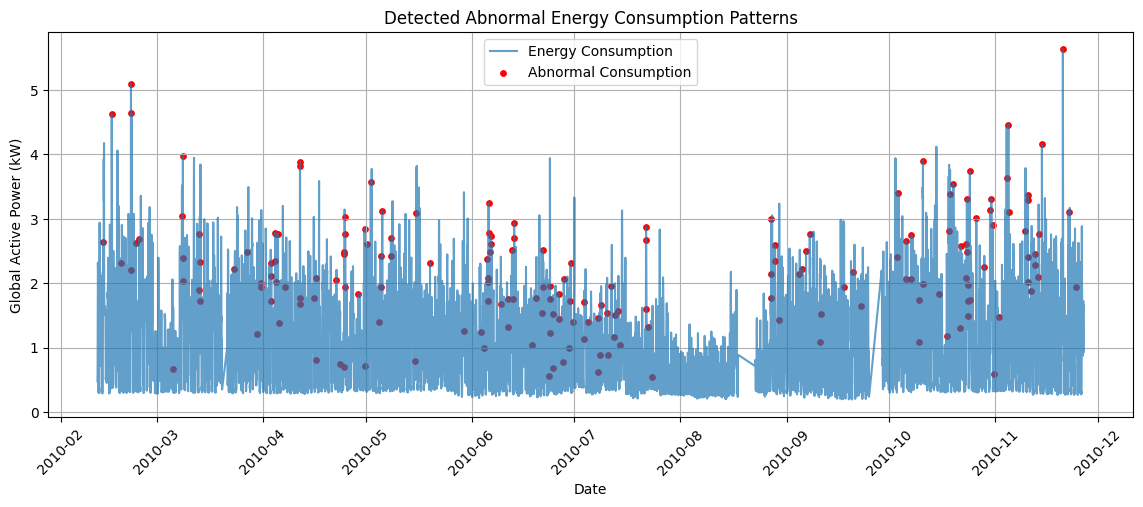


Detected Abnormal Records:
                Datetime  Actual_Energy  Reconstructed_Energy  \
42   2010-02-13 10:00:00       2.642600              3.016365   
100  2010-02-15 20:00:00       4.619633              4.536128   
165  2010-02-18 13:00:00       2.310933              2.467566   
235  2010-02-21 11:00:00       5.090800              4.877770   
236  2010-02-21 12:00:00       2.208200              2.622888   
238  2010-02-21 14:00:00       4.638200              4.626415   
268  2010-02-22 20:00:00       2.616033              3.043942   
291  2010-02-23 19:00:00       2.690767              2.961745   
527  2010-03-05 15:00:00       0.665467              0.985699   
596  2010-03-08 12:00:00       3.042467              3.387069   
597  2010-03-08 13:00:00       2.384700              2.622266   
598  2010-03-08 14:00:00       2.026333              2.422429   
599  2010-03-08 15:00:00       3.969000              4.171120   
713  2010-03-13 09:00:00       1.892400              2.176752 

In [15]:
# Separate abnormal records

abnormal_data = results[
    results['Status'] == 'Abnormal'
]

plt.figure(figsize=(14, 5))

# Actual Energy Consumption

plt.plot(
    results['Datetime'],
    results['Actual_Energy'],
    label='Energy Consumption',
    alpha=0.7
)

# Highlight Abnormal Patterns

plt.scatter(
    abnormal_data['Datetime'],
    abnormal_data['Actual_Energy'],
    color='red',
    label='Abnormal Consumption',
    s=15
)

plt.title("Detected Abnormal Energy Consumption Patterns")

plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")

plt.legend()
plt.grid()

plt.xticks(rotation=45)

plt.show()

print("\nDetected Abnormal Records:")
print(abnormal_data.head(20))

In [16]:
# Calculate evaluation metrics

mse = mean_squared_error(
    X_test,
    test_predictions
)

mae = mean_absolute_error(
    X_test,
    test_predictions
)

print("Model Evaluation Results")

print("Mean Squared Error (MSE):", mse)

print("Mean Absolute Error (MAE):", mae)

print("Anomaly Threshold:", threshold)

print("\nNormal Records:", np.sum(~anomalies))

print("Abnormal Records:", np.sum(anomalies))

print("\nAnomaly Detection Completed Successfully!")

Model Evaluation Results
Mean Squared Error (MSE): 0.0013600663409405606
Mean Absolute Error (MAE): 0.022282245724235143
Anomaly Threshold: 0.007602206074052916

Normal Records: 6735
Abnormal Records: 183

Anomaly Detection Completed Successfully!
